# Prueba individual · Sesión 03
### Career Tech Hub · Un caso de datos de principio a fin

**Nombre:** *Paola Tron Escobosa*

Trabajas con los mismos datos de la sesión. Lee antes el PDF de la prueba: ahí están las instrucciones y la rúbrica.

- Haz **al menos dos** de las partes A (pandas), B (SQL) y C (Excel o Power BI).
- La **parte D es obligatoria**.
- Este cuaderno tiene que estar en la misma carpeta que el cuaderno de la sesión, junto a la carpeta `datos`.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Las hojas del Excel (para la parte A)
dias = pd.read_excel("../datos/electricidad_para_panel.xlsx", sheet_name="dias")
generacion = pd.read_excel("../datos/electricidad_para_panel.xlsx", sheet_name="generacion")

# La base de datos (para la parte B)
conexion = sqlite3.connect("../datos/electricidad.db")

def sql(consulta):
    # Lanza una consulta y devuelve el resultado como tabla de pandas.
    return pd.read_sql(consulta, conexion)

print("Hoja dias:", dias.shape[0], "filas ·", list(dias.columns))
sql("SELECT type AS tipo, name AS nombre FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name")

Hoja dias: 1415 filas · ['fecha', 'dia_semana', 'mes', 'festivo', 'descanso', 't_med', 'demanda_gwh', 'año']


,tipo,nombre
0,table,ciudades
1,table,demanda
2,table,festivos
3,table,generacion
4,table,predicciones
5,table,tiempo
6,view,tabla_dias
7,view,temperatura_nacional


Columnas de las tablas de la base de datos:

| Tabla | Columnas |
|---|---|
| `demanda` | `fecha`, `demanda_gwh` |
| `generacion` | `fecha`, `tecnologia`, `tipo`, `gwh` |
| `tiempo` | `fecha`, `ciudad`, `t_max`, `t_min`, `t_med`, `lluvia_mm`, `viento_kmh`, `sol_mj` |
| `ciudades` | `ciudad`, `latitud`, `longitud`, `habitantes` |
| `festivos` | `fecha`, `festivo` |
| `temperatura_nacional` (vista) | `fecha`, `t_med` |
| `tabla_dias` (vista) | `fecha`, `demanda_gwh`, `t_med`, `festivo`, `demanda_ayer`, `demanda_hace_7` |

# Parte A · pandas

Usa la tabla `dias`.

**Exploración inicial**

Si bien la tabla `dias` se encuentra preparada para la presente prueba técnica, resulta necesario revisar su estructura (columnas, tipos de datos, nulos y duplicados) para poder responder a las preguntas correctamente, por lo que se realiza una breve exploración inicial. 

In [2]:
dias

,fecha,dia_semana,mes,festivo,descanso,t_med,demanda_gwh,año
0,2023-01-01,domingo,1,1,True,10.24,506.425906,2023
1,2023-01-02,lunes,1,0,False,10.25,621.645824,2023
2,2023-01-03,martes,1,0,False,9.20,677.052137,2023
3,2023-01-04,miércoles,1,0,False,7.79,689.160950,2023
4,2023-01-05,jueves,1,0,False,7.32,671.291045,2023
...,...,...,...,...,...,...,...,...
1410,2026-11-11,miércoles,11,0,False,16.12,688.687550,2026
1411,2026-11-12,jueves,11,0,False,16.39,698.606940,2026
1412,2026-11-13,viernes,11,0,False,15.05,707.449750,2026
1413,2026-11-14,sábado,11,0,True,14.13,615.539670,2026


In [3]:
#Periodo comprendido
inicio = dias["fecha"].min().strftime("%d/%m/%Y")

fin = dias["fecha"].max().strftime("%d/%m/%Y")

print("Los datos abarcan el siguiente periodo de tiempo: \n")

print("Fecha inicial: ", inicio)
print("Fecha final: ", fin)

Los datos abarcan el siguiente periodo de tiempo: 

Fecha inicial:  01/01/2023
Fecha final:  15/11/2026


Dado que la tabla contempla valores de demanda correspondiente al año en curso (2026), aún no hay datos correspondientes al mes de diciembre Asimismo, el último refistro corresponde a la fecha 15/11/2026 por lo que tampoco hay datos de demanda correspondiente a la segunda quincena de noviembre. Es importante tener en cuenta que el año no está completo a la hora de efectuar comparaciones. 

In [4]:
dias.info()

<class 'pandas.DataFrame'>
RangeIndex: 1415 entries, 0 to 1414
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   fecha        1415 non-null   datetime64[us]
 1   dia_semana   1415 non-null   str           
 2   mes          1415 non-null   int64         
 3   festivo      1415 non-null   int64         
 4   descanso     1415 non-null   bool          
 5   t_med        1415 non-null   float64       
 6   demanda_gwh  1415 non-null   float64       
 7   año          1415 non-null   int64         
dtypes: bool(1), datetime64[us](1), float64(2), int64(3), str(1)
memory usage: 88.4 KB


La tabla `dias` cuenta tiene un total de 8 columnas y 1415 filas (una por día) y puede observarse que: 

* No hay valores nulos. 
* Los tipos de datos son coherentes al tipo de variable, siendo estos:
  - datatime64 para fecha.
  - str para el nombre de los días.
  - int64 para mes y año
  - int64 para festivo,clasificados como 1 (festivo)/ 0 (no festivo).
  - float64 para temperatura media y demanda de energía.
  - bool para descanso (True/False).

In [5]:
# Se determina si hay filas duplicadas
dias.duplicated().sum()

np.int64(0)

In [6]:
#Se determina si hay fechas duplicadas
dias["fecha"].duplicated().sum()

np.int64(0)

Se observa que no hay filas duplicadas ni fechas repetidas (cada fila corresponde a un único día).

**Respuestas del punto A**

**A1.** ¿Cuántos días superaron los 800 GWh de demanda? ¿Cuántos fueron en cada año?

In [7]:
# Para determinar la cantidad de días con una demanda mayor a 800GWh, se debe:

# Seleccionar los días en los que la demanda supera los 800GWh:
d_800GWh = dias[dias["demanda_gwh"]> 800]

# Contar los registros encontrados, los cuales corresponden al periodo completo: 
cuenta_d800GWh = len(d_800GWh)

print(f"El número total de días con demanda superior a 800GWh para el periodo contemplado entre el {inicio} y el {fin} fue:", cuenta_d800GWh)

El número total de días con demanda superior a 800GWh para el periodo contemplado entre el 01/01/2023 y el 15/11/2026 fue: 115


In [8]:
#Para determinar la cantidad de días por año se debe agrupar por año y contar:
conteo = d_800GWh.groupby("año").size()

Entre el 01/01/2023 y el 15/11/2026, 115 días superaron los 800 GWh: 16 en 2023, 10 en 2024, 25 en 2025 y 64 en 2026. Salvo el descenso observado para el año 2024, la cifra aumenta, destacando el 2026 que, aunque no está completo, es más del doble que año anterior. Esto podría deberse a varios factores tales como más calor, más consumo eléctrico, etc. aunque habría que comprobarlo. Lo anterior puede sobservaser en el siguiente gráfico. 

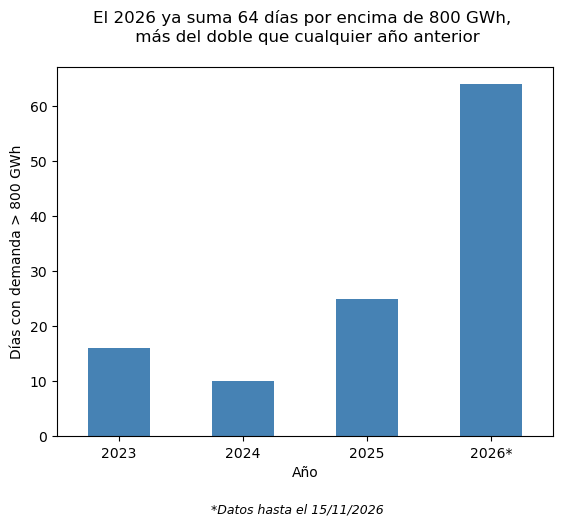

In [9]:
#Gráfico de barras

ax = conteo.plot(kind="bar", color="steelblue")
ax.set_title("El 2026 ya suma 64 días por encima de 800 GWh, \n más del doble que cualquier año anterior\n")
ax.set_xlabel("Año")
ax.set_ylabel("Días con demanda > 800 GWh")

# 1. Cambiar la etiqueta de 2026 por "2026*"
etiquetas = [f"{a}*" if a == 2026 else str(a) for a in conteo.index]
ax.set_xticklabels(etiquetas, rotation=0)

# 2. Añadir la nota debajo del gráfico
plt.figtext(0.5, -0.05, "*Datos hasta el 15/11/2026",
            ha="center", fontsize=9, style="italic")

plt.show()

In [10]:
# Se plantea la consulta SQL. Días de la semana con demanda superior a 800 GWh por año
sql_800_dia = """
SELECT strftime('%Y', fecha) AS año,
       strftime('%w', fecha) AS num_dia,
	   CASE strftime('%w', fecha)
            WHEN '0' THEN 'Domingo'
            WHEN '1' THEN 'Lunes'
            WHEN '2' THEN 'Martes'
            WHEN '3' THEN 'Miércoles'
            WHEN '4' THEN 'Jueves'
            WHEN '5' THEN 'Viernes'
            WHEN '6' THEN 'Sábado'
       END AS dia_semana,
       COUNT(*) AS dias_800
FROM demanda
WHERE demanda_gwh > 800
GROUP BY año, num_dia
ORDER BY año, num_dia;
"""

#Se construye el df:
df_800_dia = pd.read_sql(sql_800_dia, conexion)
df_800_dia

,año,num_dia,dia_semana,dias_800
0,2023,2,Martes,5
1,2023,3,Miércoles,6
2,2023,4,Jueves,3
3,2023,5,Viernes,2
4,2024,2,Martes,2
5,2024,3,Miércoles,4
6,2024,4,Jueves,3
7,2024,5,Viernes,1
8,2025,1,Lunes,3
9,2025,2,Martes,5


La demanda de energía eléctrica que supera los 800 GWh corresponde a los días de semana (laborables).

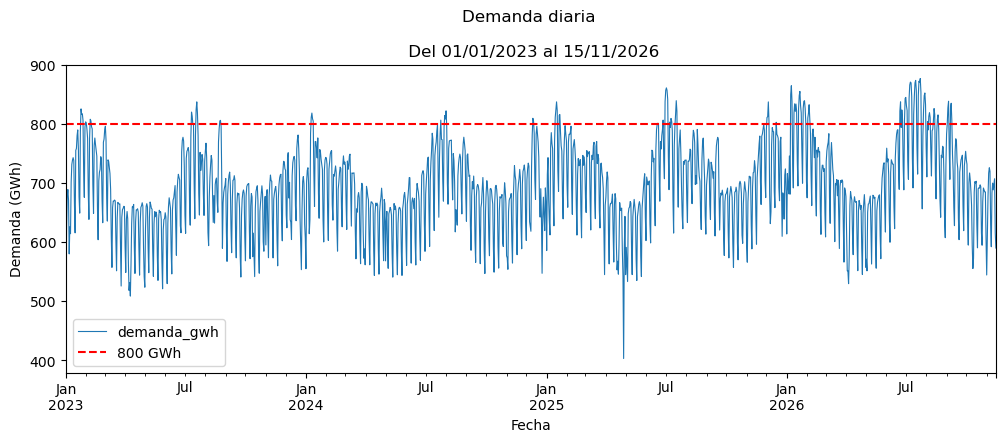

In [11]:
#Demanda diaria

ax = dias.plot(x="fecha", y="demanda_gwh", figsize=(12, 4), legend=False, linewidth=0.8)
ax.axhline(800, color="red", linestyle="--", label="800 GWh")
ax.set_title("Demanda diaria \n \n Del 01/01/2023 al 15/11/2026")
ax.set_ylabel("Demanda (GWh)")
ax.set_xlabel("Fecha")
ax.legend()
plt.show()

La gráfica muestra la demanda diaria para un periodo de casi 4 años, del 01/01/2023 al 15/11/2026. La línea roja marca el consumo de 800 GWh. Según la consulta por días de la semana, todos los días por encima de 800 GWh son laborables y en la gráfica puede sobservarse que estos días se concentran en: 

* Los meses de enero y febrero, coincidiendo con la temporada de invierno, cuyo aumento puede deberse al mayor uso de calefacción eléctrica, entre otras causas.  
* Principalmente entre julio y agosto, que corresponde al verano. En este caso, el incremento podría deberse al mayor uso de aire acondicionado.

Por otra parte, un punto que se destaca es el marcado descenso observado para finales de abril del 2025, concretamente el 28/04/2025 (403 GWh) lo cual coincide con el apagón masivo que afectó a España. 

Finalmente, los días con demanda superior a 800 GWh son cada vez más frecuentes, donde el mayor número de picos se dá en el año en 2026, a pesar de que el año aún no ha finalizado.  


**A2.** Haz una tabla con la demanda media de cada año, separando los días laborables de los días de descanso (columna `descanso`). ¿Qué porcentaje menos se gasta en un día de descanso, cada año?

In [12]:
# Para realizar la tabla es necesario agrupar por año y descanso. Se generan 3 columnas donde la primera corresponde al año, y las dos restante a
# corresponde a False (dias laborables) y True (descanso)

df_dMedia = dias.groupby(["año","descanso"])["demanda_gwh"].mean().round(2).unstack()
df_dMedia


descanso,False,True
año,,
2023,707.72,605.50
2024,710.06,612.02
2025,732.49,633.23
2026,749.86,643.03


In [13]:
#Para saber que porcentaje menos se gasta en un día de descanso respecto a un día laborable de debe calacular:
# (laborable - descanso) / laborable * 100
#True = descanso y False = Laborable, como se mencionó anteriormente.

df_dMedia["% menos en descanso"] = (df_dMedia[False] - df_dMedia[True])/df_dMedia[False]*100
df_dMedia.round(2)

descanso,False,True,% menos en descanso
año,,,
2023,707.72,605.50,14.44
2024,710.06,612.02,13.81
2025,732.49,633.23,13.55
2026,749.86,643.03,14.25


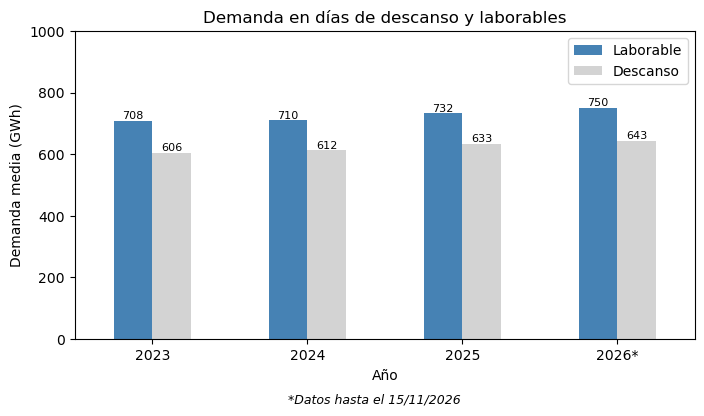

In [14]:
datos = df_dMedia.drop(columns="% menos en descanso").copy()
datos.columns = ["Laborable", "Descanso"]
datos.index = [f"{a}*" if a == 2026 else str(a) for a in datos.index]

ax = datos.plot(kind="bar", rot=0, color=["steelblue", "lightgray"], figsize=(8, 4))
ax.set_title("Demanda en días de descanso y laborables")
ax.set_xlabel("Año")
ax.set_ylabel("Demanda media (GWh)")
ax.set_ylim(0, 1000)
ax.legend(title="")

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f", fontsize=8)

plt.figtext(0.5, -0.05, "*Datos hasta el 15/11/2026",
            ha="center", fontsize=9, style="italic")
plt.show()

Se observa que en días de descanso se demanda aproximadamente entre un 13.5% y un 14.5% menos de electricidad por año que en días laborables. Esto podría deberse a que en esos días las actividades económicas como la industria y los servicios disminuyen. El gráfico de barras muestra la diferencia de consumo. 

**A3.** ¿Cuál fue el mes con mayor demanda media de los cuatro años (di el mes y el año)? ¿Y el de menor?

In [15]:
# Se calcula la demanda media agrupada por mes y año, para los 4 años:
df_dMes = dias.groupby(["año","mes"])["demanda_gwh"].mean().round(2)


In [16]:
#El mes y el año con el mayor valor son:
año_max, mes_max = df_dMes.idxmax()
# El valor máximo demandado es:
dem_max= df_dMes.max()

print(f"La mayor demanda media de energía eléctrica contemplada hasta la fecha {fin} corresponde al {mes_max}/{año_max} con un valor de {dem_max} GWh")

La mayor demanda media de energía eléctrica contemplada hasta la fecha 15/11/2026 corresponde al 7/2026 con un valor de 814.83 GWh


In [17]:
#El mes y el año con el menor valor son:
año_min, mes_min = df_dMes.idxmin()
# El valor mínimo demandado es:
dem_min= df_dMes.min()

print(f"La menor demanda media de energía eléctrica contemplada hasta la fecha {fin} corresponde al {mes_min}/{año_min} con un valor de {dem_min} GWh")

La menor demanda media de energía eléctrica contemplada hasta la fecha 15/11/2026 corresponde al 4/2023 con un valor de 610.56 GWh


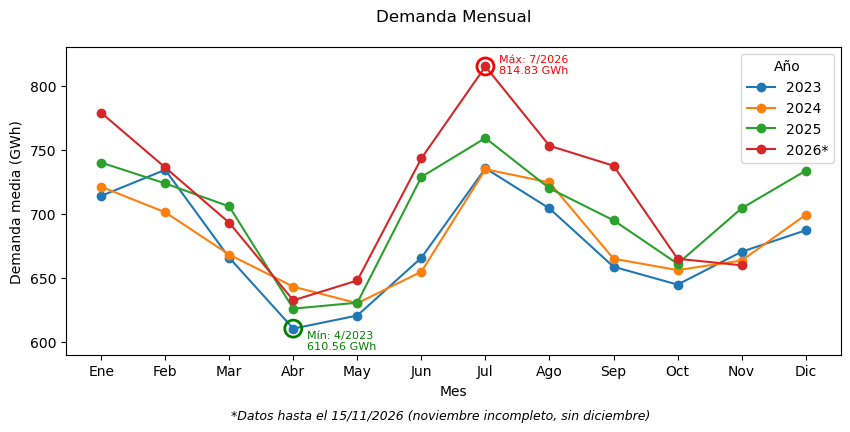

In [18]:
# Meses en filas, años en columnas
tabla_mes = df_dMes.unstack(level="año")
tabla_mes.columns = [f"{a}*" if a == 2026 else str(a) for a in tabla_mes.columns]

ax = tabla_mes.plot(marker="o", figsize=(10, 4))

# Marcar el máximo y el mínimo
ax.scatter(mes_max, dem_max, s=150, facecolors="none", edgecolors="red", linewidths=2, zorder=5)
ax.annotate(f"Máx: {mes_max}/{año_max}\n{dem_max} GWh", (mes_max, dem_max),
            textcoords="offset points", xytext=(10, -5), fontsize=8, color="red")

ax.scatter(mes_min, dem_min, s=150, facecolors="none", edgecolors="green", linewidths=2, zorder=5)
ax.annotate(f"Mín: {mes_min}/{año_min}\n{dem_min} GWh", (mes_min, dem_min),
            textcoords="offset points", xytext=(10, -15), fontsize=8, color="green")
ax.set_ylim(590, 830)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_title("Demanda Mensual\n")
ax.set_xlabel("Mes")
ax.set_ylabel("Demanda media (GWh)")
ax.legend(title="Año")

plt.figtext(0.5, -0.05, "*Datos hasta el 15/11/2026 (noviembre incompleto, sin diciembre)",
            ha="center", fontsize=9, style="italic")
plt.show()

La gráfica muestra la demanda media mensual de energía eléctrica para un periodo de casi 4 años y permite obtener las siguientes conclusiones: 

- Al año pueden observarse 2 picos (diciembre/enero y julio), coincidiendo con las temporadas de invierno y verano, donde se requiere el uso de calefacción y aire acondicionado. Los dos valles (abril y octubre) corresponden a las temporadas de primavera y otoño, cuando el clima es más templado y donde no se requiere climatizar el ambiente.
- Se observa que la demanda mensual del 2025 y, sobre todo, del 2026 están por encima de la del 2023 y 2024. Por otro lado, la variación entre el año 2023 y 2024 presenta gráficas similares. El mes de noviembre del 2026 se encuentra por debajo de los meses anteriores porque solo contempla la primera quincena por lo que en este caso debe descartarse al comparar.

In [19]:
#Se plantea consulta SQL para cual es la temperatura asociada a los picos y la los valles:
sql_dem_mensual = """
    SELECT strftime('%m', d.fecha) AS mes,
       ROUND(AVG(d.demanda_gwh), 1) AS demanda_media,
       ROUND(AVG(t.t_med), 1) AS temperatura_media
    FROM demanda AS d
    JOIN temperatura_nacional AS t ON d.fecha = t.fecha
    GROUP BY mes
    ORDER BY mes;
    """

#Se contruye el df:
df_dem_T = pd.read_sql(sql_dem_mensual, conexion)

print("La temperatura asociada a los picos y la los valles es: \n")

df_dem_T 

La temperatura asociada a los picos y la los valles es: 



,mes,demanda_media,temperatura_media
0,01,738.5,8.1
1,02,723.6,9.8
2,03,683.2,11.8
3,04,628.1,15.8
4,05,632.5,18.5
5,06,698.2,24.5
6,07,761.0,27.3
7,08,725.4,27.5
8,09,689.1,22.3
9,10,656.8,18.1


La tabla confirma lo observado en la gráfica. La demanda más baja está en los meses templados, siendo estos: Abril (15,8 °C), mayo (18,5 °C) y octubre (18,1 °C), los tres meses de menor demanda, y todos tienen temperaturas de entre 15 y 19 °C. La demanda más alta está en los dos extremos. Por el frío, enero (8,1 °C) y diciembre (8,5 °C). Por el calor, julio (27,3 °C) y agosto (27,5 °C). Es decir, la demanda no sube solo con el calor ni solo con el frío: sube cuando la temperatura se aleja de lo templado, en cualquier sentido. 

Asimismo, en la tabla puede obserbarse que agosto (27,5 °C) es más caluroso que julio (27,3 °C), sin embargo, su demanda baja, lo cual coherente con las vacaciones de agosto, cuando se reduce la actividad. 

Es importante tener en cuenta que los datos de la tabla correspondientes a los meses de noviembre y diciembre, no son del todo comparables debido a que los datos del 2026 no están completos. Los valores observados para noviembre consideran la primera quincena del mes para 2026 y para diciembre, solo se tienen en cuenta los correspondientes a los años 2023, 2024 y 2025, dado que aún no hay datos para ese mes en 2026.

Se realiza el siguiente mapa de calor

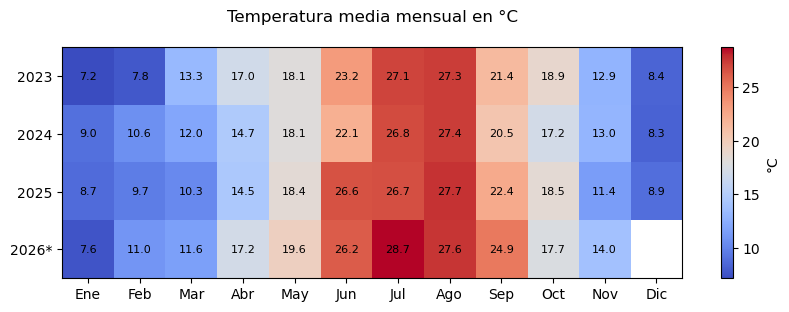

In [20]:
temp_mes = dias.groupby(["año", "mes"])["t_med"].mean().unstack(level="mes")

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(temp_mes, cmap="coolwarm", aspect="auto")

ax.set_xticks(range(12))
ax.set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_yticks(range(len(temp_mes.index)))
ax.set_yticklabels([f"{a}*" if a == 2026 else a for a in temp_mes.index])

# Escribir el valor dentro de cada celda
for i in range(temp_mes.shape[0]):
    for j in range(temp_mes.shape[1]):
        valor = temp_mes.iloc[i, j]
        if pd.notna(valor):
            ax.text(j, i, f"{valor:.1f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, label="°C")
ax.set_title("Temperatura media mensual en °C\n")
plt.show()

El mapa de calor muestra como ha ido variando la temperatura mensual a lo largo del periodo analizado y complementa lo determinado hasta el momento, se observa que: 

* Julio del 2026 constituye la celda de color rojo más intensa de todo el mapa (28,7 °C), es el mes más caluroso de los cuatro años y se corresponde con el valor máximo de demanda (814,83 GWh), por lo que el calor ayuda a explicar el pico observado en el gráfico de líneas.
* Septiembre del 2026 (24,9 °C) también es mucho más caluroso que los otros septiembres. En el gráfico de líneas, septiembre de 2026 tenía mucha más demanda que los demás años.
* Enero del 2026 (7,6 °C) es de los más fríos, y el que tuvo más demanda (779 GWh) de energía eléctrica.

Es decir, el año 2026 tuvo meses más extremos, tanto en frío como en calor, y lo cual permite explicar por qué su demanda fue la más alta.

# Parte B · SQL

Usa la función `sql("...")` con la base de datos.

**B1.** Saca los cinco días más calurosos (vista `temperatura_nacional`) junto con su demanda. ¿Son también días de mucha demanda? Explica por qué en una o dos frases.

In [21]:
#Se plantea la consulta SQL. Se sabe que para los días de la semana domingo=0 y sábado=6
sql_1 = """
       SELECT d.fecha,
       strftime('%w', d.fecha) AS dia_semana,
       d.demanda_gwh,
       t.t_med
       FROM demanda AS d
       JOIN temperatura_nacional AS t ON d.fecha = t.fecha
       ORDER BY t.t_med DESC
       LIMIT 5;
       """

#Se construye el df
df_Tmax = pd.read_sql(sql_1, conexion)

print("Demanda de los 5 días más calurosos\n")

df_Tmax.round(2)

Demanda de los 5 días más calurosos



,fecha,dia_semana,demanda_gwh,t_med
0,2025-08-16,6,712.44,31.81
1,2025-08-17,0,698.79,31.79
2,2023-08-23,3,805.11,31.61
3,2025-08-11,1,770.15,31.49
4,2025-06-29,0,707.45,31.43


Si bien el conjunto de datos abarca fechas entre el 2023 y 2026, los 5 días más calurosos corresponden a los años 2023 y 2025, donde cuatro de los cinco días caen en el mes de agosto y uno en el mes de junio, dentro de la temporada de verano. Por otra parte, el valor medio de la demanda para días de descanso fue de 633.23 GWh y de 732.49 GWh para días laborables para el año 2025; y de 707.72 GWh para los días laborables del año 2023. 

Analizando el resultado, tres de los registros son días de descanso (fin de semana) donde el 16/08/2025 es día sábado y el 29/06/2025 y el 17/08/2025 son domingo, el resto de los días se corresponden a días laborables, siendo el 23/08/23 un día miércoles y el 11/08/2025, lunes. 
Tal y como se analizó en el punto A2, la energía demandada para los días de descanso tiende a ser menor a la requerida los laborables, lo cual puede observarse al comparar el valor de la demanda de la tabla para las diferentes fechas. 

Finalmente, en todos los casos, el valor de la demanda observada supera el valor medio demandado según sea dia de descanso o laborable, lo cual sugiere que con el aumento de la temperatura ambiente se incrementa el consumo de energía eléctica por ejemplo, mayor uso de aire acondicionado. Sin embargo, solo uno (el miércoles 23/08/2023) superó los 800 GWh, ya que tres de los cinco días cayeron en fin de semana.

Se realiza el siguiente gráfico de dispersión diaria de temperatura destacando los días más calurosos. Puede observarse claramente dos bandas, una correspondiente a los días laborables (azul) y la otra a los de descanso (verde). Los días de descanso están siempre por debajo de los laborables, a cualquier temperatura.

El punto más alejado del resto de los datos (403GWh) corresponde al apagón sufrido el 29/042025.


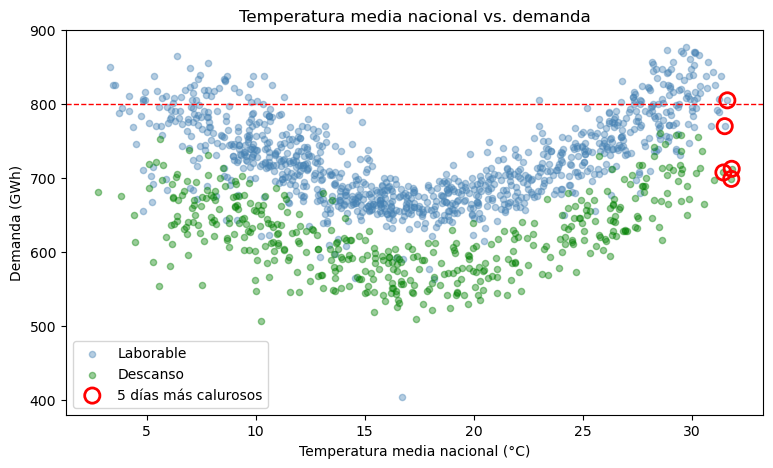

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))

# Todos los días, coloreados según sean laborables o de descanso
lab = dias[dias["descanso"] == False]
desc = dias[dias["descanso"] == True]
ax.scatter(lab["t_med"], lab["demanda_gwh"], s=20, alpha=0.4, color="steelblue", label="Laborable")
ax.scatter(desc["t_med"], desc["demanda_gwh"], s=20, alpha=0.4, color="green", label="Descanso")

# Los 5 días más calurosos, destacados
ax.scatter(df_Tmax["t_med"], df_Tmax["demanda_gwh"], s=120, facecolors="none",
           edgecolors="red", linewidths=2, label="5 días más calurosos")

ax.axhline(800, color="red", linestyle="--", linewidth=1)
ax.set_title("Temperatura media nacional vs. demanda")
ax.set_xlabel("Temperatura media nacional (°C)")
ax.set_ylabel("Demanda (GWh)")
ax.legend()
plt.show()

**B2.** Para cada año, calcula la generación solar fotovoltaica en TWh y qué porcentaje supone de toda la generación del año.

In [23]:
#Se explora los diferentes tipos de tecnología empleada en la generación de energía: 
sql_2 = """
    SELECT DISTINCT tecnologia 
    FROM generacion;
    """

#Se construye el df
df_Tec = pd.read_sql(sql_2, conexion)

print("Las tecnologías empleadas en la generación de energía son: \n")

df_Tec

Las tecnologías empleadas en la generación de energía son: 



,tecnologia
0,Hidráulica
1,Nuclear
2,Carbón
3,Motores diésel
4,Turbina de gas
5,Turbina de vapor
6,Ciclo combinado
7,Hidroeólica
8,Eólica
9,Solar fotovoltaica


In [24]:
# Se calcula la generación total de energía solar fotovoltaica en TWh por año: 
sql_Fotovoltaica_año = """
                       SELECT strftime('%Y', fecha) AS año,
                       SUM(gwh) / 1000.0 AS fotovoltaica_twh
                       FROM generacion
                       WHERE tecnologia = 'Solar fotovoltaica'
                       GROUP BY año;
                       """
#Se construye el df
df_Fotovoltaica_año = pd.read_sql(sql_Fotovoltaica_año, conexion)

print("Generación anual de energía solar fotovoltaica en TWh: \n")

df_Fotovoltaica_año.round(2)

Generación anual de energía solar fotovoltaica en TWh: 



,año,fotovoltaica_twh
0,2023,37.45
1,2024,44.60
2,2025,50.29
3,2026,55.41


In [25]:
# Se calcula la generación total de energía en TWh por año: 
sql_energia_anual = """
                       SELECT strftime('%Y', fecha) AS año,
                       SUM(gwh) / 1000.0 AS total_twh
                       FROM generacion
                       GROUP BY año;
                       """
#Se construye el df
df_energia_anual = pd.read_sql(sql_energia_anual, conexion)

print("Generación anual de energía en TWh: \n")

df_energia_anual.round(2)

Generación anual de energía en TWh: 



,año,total_twh
0,2023,263.61
1,2024,262.43
2,2025,272.41
3,2026,247.37


In [26]:
#Se unen ambas tablas para generar una nueva donde se calcula el porcentaje:
resultado = df_Fotovoltaica_año.merge(df_energia_anual, on = "año")
resultado["porcentaje"] = resultado["fotovoltaica_twh"] / resultado["total_twh"] * 100
resultado.round(2)

,año,fotovoltaica_twh,total_twh,porcentaje
0,2023,37.45,263.61,14.21
1,2024,44.60,262.43,16.99
2,2025,50.29,272.41,18.46
3,2026,55.41,247.37,22.40


La tabla anterior muestra la generación anual de energía eléctrica mediante tecnología solar fotovoltaica en TWh y su porcentaje correspondiente. Puede observarse que la fotovoltaica pasó de 37,45 TWh (14,2 %) en 2023 a 50,29 TWh (18,5 %) en 2025. Aunque el año 2026 no se encuentra completo, puede observarse una tendencia ascendente a la generación de energía eléctrica mediante el uso de esta tecnología. 

Se realiza la siguiente gráfica de barras para mostrar el resultado anterior.

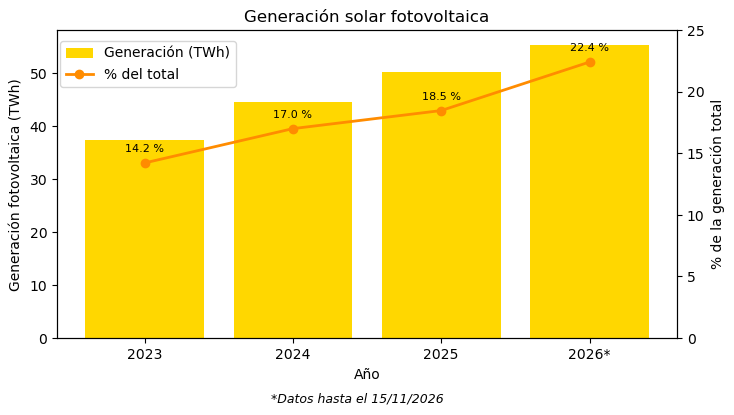

In [27]:
res = resultado.copy()
res["año"] = [f"{a}*" if a == "2026" else a for a in res["año"]]

fig, ax1 = plt.subplots(figsize=(8, 4))

# Barras: TWh (eje izquierdo)
ax1.bar(res["año"], res["fotovoltaica_twh"], color="gold", label="Generación (TWh)")
ax1.set_ylabel("Generación fotovoltaica (TWh)")
ax1.set_xlabel("Año")

# Línea: porcentaje (eje derecho)
ax2 = ax1.twinx()
ax2.plot(res["año"], res["porcentaje"], color="darkorange", marker="o", linewidth=2, label="% del total")
ax2.set_ylabel("% de la generación total")
ax2.set_ylim(0, 25)

# Valores encima
for i, v in enumerate(res["porcentaje"]):
    ax2.annotate(f"{v:.1f} %", (i, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)

ax1.set_title("Generación solar fotovoltaica")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.87))
plt.figtext(0.5, -0.05, "*Datos hasta el 15/11/2026", ha="center", fontsize=9, style="italic")
plt.show()

La gráfica a continuación muestra la generación de energía eléctrica para la tecnología solar fotovoltica. 

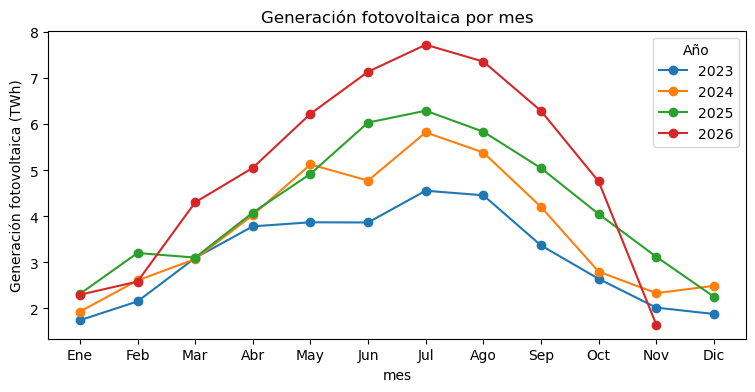

In [28]:
sql_fv_mes = """
SELECT strftime('%Y', fecha) AS año,
       CAST(strftime('%m', fecha) AS INTEGER) AS mes,
       SUM(gwh) / 1000.0 AS fv_twh
FROM generacion
WHERE tecnologia = 'Solar fotovoltaica'
GROUP BY año, mes;
"""
fv_mes = pd.read_sql(sql_fv_mes, conexion).pivot(index="mes", columns="año", values="fv_twh")

ax = fv_mes.plot(marker="o", figsize=(9, 4))
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_title("Generación fotovoltaica por mes")
ax.set_ylabel("Generación fotovoltaica (TWh)")
ax.legend(title="Año")
plt.show()

La gráfica muestra que la generación por medio de tecnología fotovoltaica tiene su pico máximo en el mes de julio, independientemente del año, y que cada línea queda por encima de la del año anterior casi todos los meses. Asimismo, los meses de mayor generación se corresponden a la temporada de verano mientras que los de menor a los meses de invierno. Esto es debido a que la radiación solar aumenta en los meses de verano. 

En noviembre, la línea del año 2026 cae por debajo de la de los otros años, porque los datos solo contemplan la primera quincena, como se ha mencionado en otras ocasiones. 

**B3.** ¿Cuántos días de lluvia (1 mm o más) ha tenido cada ciudad? Ordena de más a menos.

En un periodo de casi 4 años, la ciudad con más días con precipitaciones mayores o iguales a 1mm es Bilbao con 611 días, seguida por Barcelona y Madrid con 350 y 305 días, respectivamente. La ciudad con menos días de lluvia ha sido Valencia con 218 días. 

In [29]:
# Consulta SQL
sql_lluvia_1mm = """
    SELECT ciudad, COUNT(*) AS dias_lluvia
    FROM tiempo
    WHERE lluvia_mm >=1
    GROUP BY ciudad
    ORDER BY dias_lluvia DESC;
    """
#Se construye el df
df_lluvia_mm = pd.read_sql(sql_lluvia_1mm, conexion)

print("Días con precipitación mayor o igual a 1mm por ciudad: \n")

df_lluvia_mm  


Días con precipitación mayor o igual a 1mm por ciudad: 



,ciudad,dias_lluvia
0,Bilbao,611
1,Barcelona,350
2,Madrid,305
3,Zaragoza,269
4,Sevilla,239
5,Valencia,218


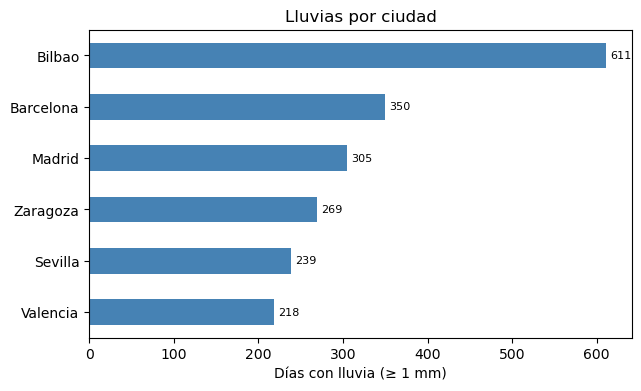

In [30]:
#Gráfico de barras

ax = df_lluvia_mm.sort_values("dias_lluvia").plot(
    kind="barh", x="ciudad", y="dias_lluvia", legend=False, color="steelblue", figsize=(7, 4))

for barras in ax.containers:
    ax.bar_label(barras, fontsize=8, padding=3)

ax.set_title("Lluvias por ciudad")
ax.set_xlabel("Días con lluvia (≥ 1 mm)")
ax.set_ylabel("")
plt.show()

**Reto (opcional).** Con `LAG`, saca los tres días en que la demanda más subió respecto al día anterior. ¿Qué pasó en el primero?

In [31]:
# Se plantea la consulta con lag
sql_reto = """
 SELECT fecha,
       demanda_gwh,
       demanda_anterior,
       demanda_gwh - demanda_anterior AS subida
 FROM (
    SELECT fecha,
           demanda_gwh,
           LAG(demanda_gwh) OVER (ORDER BY fecha) AS demanda_anterior
    FROM demanda
 )
 ORDER BY subida DESC
 LIMIT 3;
 """
#Se construye el df
df_reto = pd.read_sql(sql_reto, conexion)

print("Los tres días en los que la demanda más subió respecto al día anterior: \n")

df_reto.round(2)

Los tres días en los que la demanda más subió respecto al día anterior: 



,fecha,demanda_gwh,demanda_anterior,subida
0,2025-04-29,590.01,403.30,186.71
1,2026-01-07,849.73,681.28,168.44
2,2023-07-10,778.80,628.91,149.89


In [32]:
#Comprobación del cálculo anterior con diff
# Comprobación con pandas: mismo cálculo con diff()
dias["subida"] = dias["demanda_gwh"].diff().round(2)
dias.nlargest(3, "subida")[["fecha", "demanda_gwh", "subida"]]

,fecha,demanda_gwh,subida
849,2025-04-29,590.008854,186.71
1102,2026-01-07,849.726680,168.44
190,2023-07-10,778.800770,149.89


La tabla muestra los tres días en que la demanda más subió respecto al día anterior. La subida reflejada para el día 29/04/2025 (+186,71 GWh) no se debió a un aumento real del consumo, sino a que el día anterior, 28 de abril, un gran apagón dejó sin electricidad a la península ibérica y la demanda cayó a 403 GWh. Al día siguiente se recuperó parcialmente (590 GWh). 
Las otras dos subidas también son rebotes tras un día de poca actividad: el 07/01/2026, tras el festivo de Reyes, y el 10/07/2023, un lunes después de un domingo.

# Parte C · Excel o Power BI

Esta parte no se hace en el cuaderno. Abre `datos/electricidad_para_panel.xlsx` en Excel o cárgalo en Power BI.

**C1.** Haz una tabla dinámica (en Power BI, una matriz) con la demanda media: los meses en filas y los años en columnas. Hay una celda que no se puede comparar con las demás. ¿Cuál es y por qué?

Como se ha mencionado anteriormente, por tratarse del año en curso, el año 2026 no se encuentra completo, los datos llegan hasta el 15/11/2026. La celda que NO se puede comparar pertenece al mes de noviembre del 2026 con una demanda media de 659.91 GWh, cuyo valor corresponde a la primera quincena del mes y no al mes completo como en el caso de los años anteriores, por lo tanto sería incorrecto comparar noviembre/2026 con el mes de noviembre de otros años. 
Por otro lado, la celda de diciembre del 2026 se encuentra vacía porque aún no hay datos.

Entrega una captura de cada una. Puedes pegarlas en un documento o guardarlas como imagen.

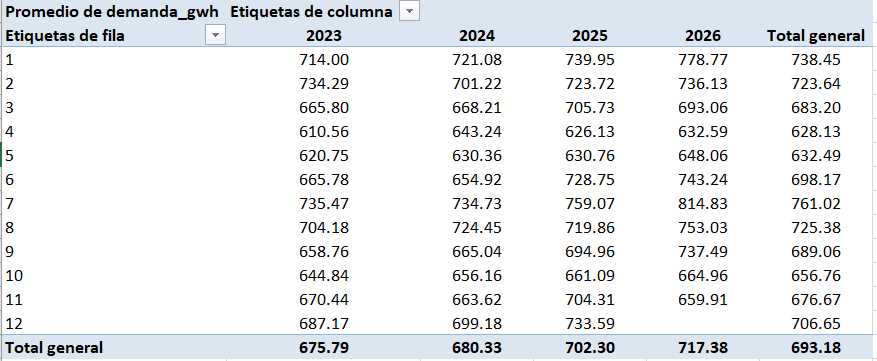

**C2.** Haz un gráfico de la generación de 2025 por tecnología (hoja `generacion`), ordenado de mayor a menor. Ponle un título que diga la conclusión, no solo el tema.

Tanto en la tabla como en la gráfica puede observarse que cinco de las quince tecnologías empleadas generaron el 88.25% (240389.47 GWh) de la electricidad en el año 2025. Encabeza la lista la eólica con un 21.59%, seguida por la nuclear (19.03%), la solar fotovoltaica (18.46%), el ciclo combinado (16.79%) y la hidráulica (12.37%). De las tecnologías mencionadas, tres son renovables (eólica, solar fotovoltaica e hidráulica) y aportan el 52.42% mientras que las dos no renovables (nuclear y ciclo combinado) contribuyen en un 35.82%.  

El resto de las tecnologías empleadas aportaron un 11.75% (32015.88 GWh) de la generación de electricidad para ese mismo año. 


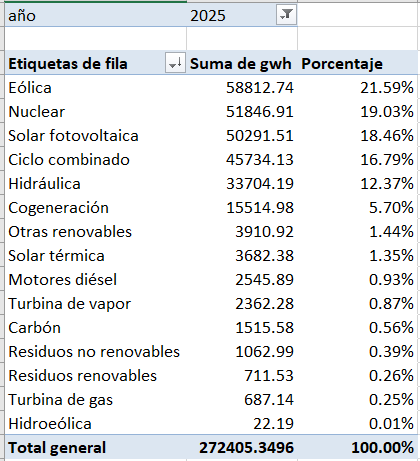

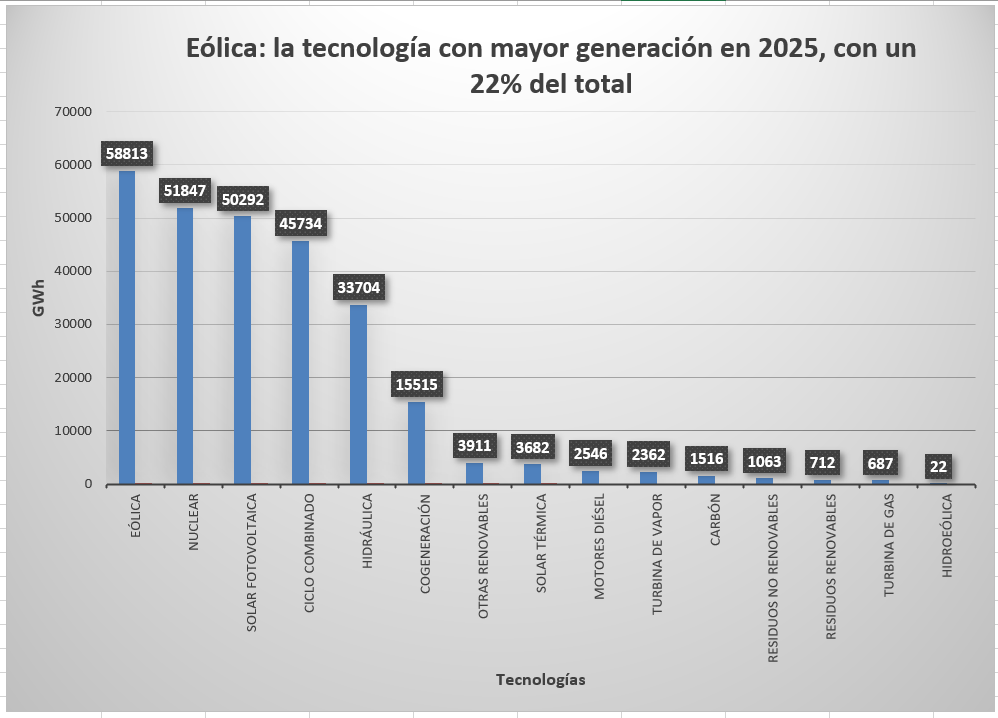

# Parte D · Explica (obligatoria)

Contesta con tus palabras. Frases cortas.

**D1.** Elige una decisión que hayas tenido que tomar en esta prueba y explica por qué la tomaste (4 a 6 líneas).

En la pregunta B1 tuve que decidir con qué comparar la demanda de los cinco días más calurosos para saber si era alta. Podía haber usado la media anual o la media de su mismo tipo de día (laborable o descanso). Elegí la segunda porque tres de los cinco días cayeron en fin de semana y en la pregunta A2 se observó que la demanda los fines de semana caía entre un 13.5 y 14.5%, compararlo con la demanda anual hubiese introducido un error en la conclusión. Esto permitió ver que los cinco días analizados superaban la media de su tipo de día lo que sugiere que el calor sí aumenta la demanda. 

**D2.** Cuenta tu resultado más interesante a alguien que no sabe de datos (3 líneas).

Los resultados más interesantes fueron los relacionados con las tecnología de generación de energía eléctica dado que denotan que las tecnologías renovables han comenzado a ganar terreno frente a las de uso convencional. En el año 2025, más de la mitad de la energía eléctrica generada se obtuvo a partir del viento (eólica), del sol (solar fotovoltaica) y del agua (hidráulica). La energía solar fotovoltaica, obtenida a partir del sol, pasó de un 14.21% a 18.46% en dos años. 

**D3.** Di un límite de tu análisis, o algo que comprobarías si tuvieras más tiempo.

* El año 2026 no está completo por tratarse del año en curso (datos hasta 15/11/2026), lo cuale afecta a los resultados. Podrías realizarse compararaciones considerando de enero a octubre de todos los años o bien descartarse el año 2026, dependiendo del análisis.
* Cinco días no son suficientes para demostrar que la demanda aumenta con el calor. Podría discriminarse por estaciones (invierno/verano) o bien tener en cuenta la temperatura de todos los días de verano, por año. Sería interesante contar con la demanda por sector, lo cual permitiría conocer la distribución de la energía.

**D4.** Si has usado una IA, di para qué y cómo comprobaste que el resultado era correcto. Si no la has usado, dilo.

La IA se usó:

* Como asistente de código, para corregir la sintaxis y revisar errores.
* Como asistente de gráfico, se le pidió a la IA que diera el código para graficar los resultados.   
* Como asistente de las consultas SQL. Para comprobar los resultados obtenidos, primero las consultas se ejecutaron en SQLite dado que permite explorar las diferentes tablas y posteriormente se trasladaron a Python. Así mismo, además de las consultas requeridas en el punto 3, se plantearon consultas como método de verificación de resultados en los diferentes apartados (ver carpeta consultas).
